# When the world No. 1 loses

How often does the lower-ranked player win a WTA singles match, and how much does the distance between two rankings tell us?

This notebook walks through the analysis with the same `wta_upsets` modules that the command line uses (`python -m wta_upsets`). It reads the bundled season files and writes nothing to disk. Match data: Jeff Sackmann / Tennis Abstract, CC BY-NC-SA 4.0.

In [1]:
import sys
from pathlib import Path

# Works whether the notebook is run from the repository root or from notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "wta_upsets").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd

from wta_upsets.benchmark import (
    fit_slope,
    predict_upset,
    rank_ratio_feature,
    run_benchmark,
)
from wta_upsets.figure import plot_upset_rates
from wta_upsets.matches import (
    EXCLUSION_REASONS,
    audit_exclusions,
    available_seasons,
    load_matches,
    select_matches,
)
from wta_upsets.rates import upset_rates

DATA = ROOT / "data"
pd.set_option("display.precision", 6)

# The package draws headlessly; switch to inline figures for the notebook.
%matplotlib inline

## 1. Match selection

Each season file is read as raw text. The season label is the year in the file name, because an event can begin in the preceding December.

A match is eligible when it passes six checks, applied in order:

1. tour level `G`, `PM`, `P`, `I`, `F`, `D` or `O`
2. hard, clay or grass surface
3. valid date
4. both rankings are positive integers
5. the two rankings differ
6. a finished, nonempty score (no `RET`, `W/O`, `DEF` or `ABD`)

A row that fails is counted once, at its first failed check, so the audit columns add up to the source rows.

In [2]:
seasons = available_seasons(DATA)
raw = load_matches(DATA, seasons)
print(f"Seasons {seasons[0]}-{seasons[-1]}: {len(raw):,} source rows")

audit = audit_exclusions(raw)
assert (audit[[*EXCLUSION_REASONS, "eligible"]].sum(axis=1) == audit["source_rows"]).all()
audit.set_index("season")

Seasons 2022-2025: 10,888 source rows


,source_rows,lower_tier,surface,date,ranking,equal_ranks,score,eligible
season,,,,,,,,
2022,2594,0,0,0,41,0,116,2437
2023,2810,0,0,0,69,0,99,2642
2024,2689,31,57,0,13,0,102,2486
2025,2795,215,36,0,12,0,89,2443


In [3]:
matches = select_matches(raw)
print(f"{len(matches):,} eligible matches, {matches['upset'].sum():,} upsets "
      f"({matches['upset'].mean():.1%})")
matches.head()

10,008 eligible matches, 3,638 upsets (36.4%)


,season,date,tourney_level,surface,winner_rank,loser_rank,rank_gap,upset
0,2022,2022-01-03,P,Hard,1,14,13,False
1,2022,2022-01-03,P,Hard,1,9,8,False
2,2022,2022-01-03,P,Hard,14,105,91,False
3,2022,2022-01-03,P,Hard,1,12,11,False
4,2022,2022-01-03,P,Hard,9,27,18,False


## 2. Upset rates by ranking gap and surface

An upset means the player with the larger pre-match ranking number won. The table has one row for every combination of surface and ranking gap, including the `All` totals, with a 95% Wilson interval for each rate. The intervals treat matches as independent; players recur across events, so they can understate uncertainty.

In [4]:
rates = upset_rates(matches)
rates.set_index(["surface", "rank_gap"])

matches  upsets  upset_rate  wilson_low  wilson_high
surface rank_gap                                                      
All     All         10008    3638    0.363509    0.354139     0.372984
        1-10         1334     612    0.458771    0.432187     0.485591
        11-25        1847     834    0.451543    0.428972     0.474316
        26-50        2348     883    0.376065    0.356689     0.395845
        51-100       2308     746    0.323224    0.304450     0.342585
        101+         2171     563    0.259327    0.241328     0.278177
Hard    All          6168    2260    0.366407    0.354469     0.378511
        1-10          871     407    0.467279    0.434361     0.500484
        11-25        1182     526    0.445008    0.416901     0.473473
        26-50        1517     570    0.375742    0.351713     0.400398
        51-100       1396     453    0.324499    0.300449     0.349511
        101+         1202     304    0.252912    0.229152     0.278246
Clay    All          2642     925    0.350114    0.332154     0.368508
        1-10          309     137    0.443366    0.389007     0.499115
        11-25         444     201    0.452703    0.407006     0.499211
        26-50         571     212    0.371278    0.332633     0.411644
        51-100        603     189    0.313433    0.277687     0.351541
        101+          715     186    0.260140    0.229325     0.293518
Grass   All          1198     453    0.378130    0.351102     0.405938
        1-10          154      68    0.441558    0.365500     0.520461
        11-25         221     107    0.484163    0.419111     0.549756
        26-50         260     101    0.388462    0.331252     0.448919
        51-100        309     104    0.336570    0.286175     0.390977
        101+          254      73    0.287402    0.235240     0.345898

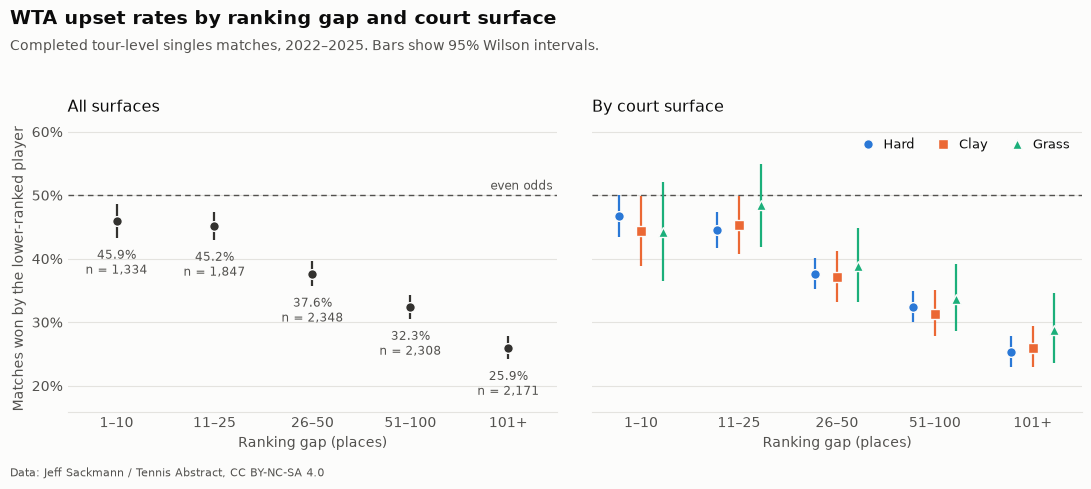

In [5]:
fig = plot_upset_rates(rates, seasons)

## 3. Retrospective held-out benchmark

The model has one feature, `log(larger rank / smaller rank)`, which is the same whichever player wins and so is known before the match. There is no intercept: as the ranks converge the upset probability tends to one half. The slope minimises the summed log loss plus `beta**2 / 2`.

Both the model and a constant baseline (the training upset rate) are fitted on the earlier seasons and scored on the latest season only. This is a retrospective evaluation: the descriptive tables above already include the latest season, so it is held out of the fit but was not unseen when the analysis was designed. Lower Brier score and log loss are better.

In [6]:
benchmark = run_benchmark(matches)
benchmark.set_index("model")

,train_seasons,test_season,train_matches,test_matches,parameter,estimate,brier_score,log_loss
model,,,,,,,,
training_upset_rate,2022-2024,2025,7565,2443,upset_probability,0.360079,0.234354,0.661543
rank_ratio_logistic,2022-2024,2025,7565,2443,slope,-0.522381,0.221253,0.632290


What the fitted slope means for a few pairings. A ten-place gap near the top of the rankings is a much larger ratio than the same gap further down.

In [7]:
train = matches[matches["season"] < matches["season"].max()]
beta = fit_slope(rank_ratio_feature(train["winner_rank"], train["loser_rank"]), train["upset"])

pairings = pd.DataFrame(
    {"higher_ranked": [5, 105, 1, 1], "lower_ranked": [15, 115, 20, 164]}
)
pairings["rank_ratio"] = pairings["lower_ranked"] / pairings["higher_ranked"]
pairings["upset_probability"] = predict_upset(
    rank_ratio_feature(pairings["higher_ranked"], pairings["lower_ranked"]), beta
)
pairings

,higher_ranked,lower_ranked,rank_ratio,upset_probability
0,5,15,3.000000,0.360339
1,105,115,1.095238,0.488122
2,1,20,20.000000,0.172943
3,1,164,164.000000,0.065127


The fitted probabilities use rankings alone. A single retrospectively held-out season is one comparison, not a general claim about how well rankings forecast matches.